# Modell: Regression und k-means

**ZHAW Data Analytics HS2026 · Gruppenprojekt «Strompreise der Gemeinden» · Teil Subraj**

Dieses Notebook deckt Pflicht 5 (Modell mit Vergleich über die Zeit), Pflicht 6 (Modellgüte), Pflicht 7 (Interpretation) und Bonus 5 (k-means zusätzlich zum Modell) ab. Es baut auf `03_analyse_subraj.ipynb` auf: Die dort getroffenen Festlegungen (Abschnitt 9) werden hier umgesetzt.

**Forschungsfrage:** Welche Merkmale einer Gemeinde erklären die Höhe ihres Strompreises für Haushalte, und haben sich diese Zusammenhänge mit dem Preisanstieg 2023 verändert?

| Abschnitt | Inhalt |
|---|---|
| 0 | Daten laden und Merkmale aufbereiten |
| 1 | Modellwahl: Variablen und Multikollinearität |
| 2 | Schätzverfahren: OLS mit nach Netzbetreiber geclusterten Standardfehlern |
| 3 | Modell A: dieselben Merkmale für drei Jahre und zwei Anstiege |
| 4 | Modell B: zusätzlich Kanton |
| 5 | Modell C: auf Ebene der Netzbetreiber |
| 6 | Modellgüte ausserhalb der Stichprobe |
| 7 | Residuen |
| 8 | k-means: Gemeindetypen |
| 9 | Fazit |

## 0 · Daten laden

Wie in Notebook 03: Analysetabelle per SQL aus der SQLite-Datenbank, Kanton, Sprachregion, Gemeindetyp und Netzbetreiber aus Lennys verbundener Tabelle.

Neu dazu kommt `anz_gemeinden_betreiber`: die Zahl der Gemeinden, die der Netzbetreiber 2027 in der Kategorie H4 beliefert (Integrationsdokumentation, Abschnitt 7b). Sie dient als Mass für die **Grösse des Netzbetreibers**.

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GroupKFold, KFold
from sklearn.preprocessing import StandardScaler


def finde_wurzel(start: Path) -> Path:
    for ordner in [start, *start.parents]:
        if (ordner / "daten").is_dir() and (ordner / "scripts").is_dir():
            return ordner
    raise RuntimeError(f"Repo-Wurzel von {start} aus nicht gefunden")


WURZEL = finde_wurzel(Path.cwd().resolve())
JAHRE = [2021, 2024, 2027]
FARBE = {"total_2021": "#2a78d6", "total_2024": "#eb6834", "total_2027": "#1baf7a",
         "anstieg_21_24": "#e87ba4", "anstieg_21_27": "#6250d6"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#898781",
    "ytick.color": "#898781", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

con = sqlite3.connect(WURZEL / "sql" / "strompreise.db")
df = pd.read_sql("SELECT * FROM v_analyse", con)
con.close()

zusatz = pd.read_csv(WURZEL / "daten" / "verbunden" / "strompreise_gemeinden.csv",
                     usecols=["gemeinde_nr", "netzbetreiber_id", "netzbetreiber", "kanton",
                              "sprachregion", "gemeindetyp_9", "anz_gemeinden_betreiber"])
df = df.merge(zusatz, on="gemeinde_nr", how="left", validate="one_to_one")
assert len(df) == 2087 and df["kanton"].notna().all()

# Zielgrössen
df["anstieg_21_24"] = df["total_2024"] - df["total_2021"]
df["anstieg_21_27"] = df["total_2027"] - df["total_2021"]

# Merkmale, rechtsschiefe logarithmiert (Begründung: Notebook 03, Abschnitt 5.1)
df["log_dichte"] = np.log10(df["dichte"])
df["log_flaeche"] = np.log10(df["flaeche_total"])
df["log_betreibergroesse"] = np.log10(df["anz_gemeinden_betreiber"])
df["beschaeftigte_pro_einw"] = df["beschaeftigte"] / df["einwohner"]

ZIELE = {"total_2021": "Preis 2021", "total_2024": "Preis 2024", "total_2027": "Preis 2027",
         "anstieg_21_24": "Anstieg 21–24", "anstieg_21_27": "Anstieg 21–27"}
print(f"{len(df)} Gemeinden, {df['netzbetreiber_id'].nunique()} Netzbetreiber")

2087 Gemeinden, 485 Netzbetreiber

## 1 · Modellwahl

### 1.1 Welche Merkmale ins Modell kommen

| Merkmal | im Modell | Begründung |
|---|---|---|
| Dichte (log) | ja | städtisch oder ländlich, in Notebook 03 der stärkste Zusammenhang mit dem Anstieg |
| Fläche (log) | ja | grosse Fläche bedeutet viele Leitungskilometer pro Kunde |
| Anteil 65+ | ja | in Notebook 03 robust mit dem Anstieg verbunden |
| Grösse des Netzbetreibers (log) | ja | grosse Betreiber kaufen Strom in grösseren Mengen und über längere Zeiträume ein |
| Sprachregion | ja, als Dummy | Vergleich der Regionen ist Teil der Fragestellung; Referenz ist die Deutschschweiz |
| Einwohner | nein | ist Dichte mal Fläche; mit beiden zusammen wäre das Modell exakt kollinear |
| Beschäftigte | nur in einer Variante | fehlt bei 88 Gemeinden, korreliert mit den Einwohnern zu 0.94; als Anteil pro Einwohner in Abschnitt 3.4 |
| Kanton | in Modell B | erklärt viel, verdeckt aber, welche Eigenschaft dahintersteht |

### 1.2 Multikollinearität

Der Varianzinflationsfaktor (VIF) misst, wie gut sich ein Merkmal aus den anderen vorhersagen lässt. Werte unter 5 gelten als unproblematisch.

In [2]:
MERKMALE = ["log_dichte", "log_flaeche", "anteil_65plus", "log_betreibergroesse"]
NAME = {"log_dichte": "Dichte (log)", "log_flaeche": "Fläche (log)", "anteil_65plus": "Anteil 65+",
        "log_betreibergroesse": "Betreibergrösse (log)", "beschaeftigte_pro_einw": "Beschäftigte pro Einw.",
        "Französisch": "Französisch", "Italienisch": "Italienisch", "Rätoromanisch": "Rätoromanisch"}


def vif(daten: pd.DataFrame) -> pd.Series:
    werte = {}
    for spalte in daten:
        andere = daten.drop(columns=spalte)
        r2 = LinearRegression().fit(andere, daten[spalte]).score(andere, daten[spalte])
        werte[NAME.get(spalte, spalte)] = 1 / (1 - r2)
    return pd.Series(werte, name="VIF")


print(df[MERKMALE].corr().round(2).rename(index=NAME, columns=NAME), "\n")
vif(df[MERKMALE]).round(2)

                       Dichte (log)  Fläche (log)  Anteil 65+  Betreibergrösse (log)
Dichte (log)                   1.00         -0.53       -0.30                  -0.04
Fläche (log)                  -0.53          1.00        0.24                  -0.22
Anteil 65+                    -0.30          0.24        1.00                  -0.06
Betreibergrösse (log)         -0.04         -0.22       -0.06                   1.00 

Dichte (log)             1.52
Fläche (log)             1.53
Anteil 65+               1.11
Betreibergrösse (log)    1.09
Name: VIF, dtype: float64

Alle VIF liegen weit unter 5. Die stärkste Korrelation besteht zwischen Dichte und Fläche (−0.53): Grossflächige Gemeinden sind meist dünn besiedelt. Das ist unproblematisch.

### 1.3 Standardisierung

Die Merkmale werden standardisiert (Mittelwert 0, Standardabweichung 1). Damit sind die Koeffizienten direkt vergleichbar: Jeder Koeffizient sagt, um wie viele Rappen pro kWh sich der Preis im Mittel unterscheidet, wenn das Merkmal um eine Standardabweichung höher ist und die anderen gleich bleiben. Die Sprachregionen bleiben Dummies (0 oder 1), ihre Koeffizienten sind Unterschiede zur Deutschschweiz in Rappen.

In [3]:
def standardisiert(daten: pd.DataFrame, spalten: list) -> pd.DataFrame:
    return (daten[spalten] - daten[spalten].mean()) / daten[spalten].std()


def regionen_dummies(sprachregion: pd.Series) -> pd.DataFrame:
    return (pd.get_dummies(sprachregion)
              .reindex(columns=["Französisch", "Italienisch", "Rätoromanisch"], fill_value=False)
              .astype(float))


X_A = pd.concat([standardisiert(df, MERKMALE), regionen_dummies(df["sprachregion"])], axis=1)
print("Eine Standardabweichung entspricht:")
for m, s in df[MERKMALE].std().items():
    faktor = f" (Faktor {10 ** s:.1f} auf der Originalskala)" if m.startswith("log_") else " Prozentpunkten"
    print(f"  {NAME[m]:<24}{s:.2f}{faktor}")

Eine Standardabweichung entspricht:
  Dichte (log)            0.62 (Faktor 4.1 auf der Originalskala)
  Fläche (log)            0.47 (Faktor 3.0 auf der Originalskala)
  Anteil 65+              4.38 Prozentpunkten
  Betreibergrösse (log)   0.92 (Faktor 8.2 auf der Originalskala)

## 2 · Schätzverfahren

Geschätzt wird eine lineare Regression mit der Methode der kleinsten Quadrate (OLS). Die Koeffizienten sind dieselben wie bei `sklearn.LinearRegression` oder `statsmodels.OLS`.

Anders sind die **Standardfehler**. Die Gemeinden eines Netzbetreibers haben denselben Preis, ihre Fehler sind also nicht unabhängig (Notebook 03, Abschnitt 7). Gewöhnliche Standardfehler wären dann zu klein und die p-Werte zu optimistisch. Deshalb werden die Standardfehler **nach Netzbetreiber geclustert** (Cluster-robuste Kovarianz nach Liang und Zeger, mit der üblichen Korrektur für kleine Stichproben):

$$\hat V = (X'X)^{-1} \Big(\sum_{g} X_g' \hat e_g \hat e_g' X_g\Big) (X'X)^{-1} \cdot \frac{G}{G-1} \cdot \frac{N-1}{N-K}$$

Dabei ist $g$ ein Netzbetreiber, $G$ ihre Zahl (485), $N$ die Zahl der Gemeinden und $K$ die Zahl der Koeffizienten. Die p-Werte kommen aus einer t-Verteilung mit $G-1$ Freiheitsgraden. Das entspricht `statsmodels.OLS(...).fit(cov_type="cluster", ...)`.

In [4]:
def ols_geclustert(y: pd.Series, X: pd.DataFrame, cluster: pd.Series) -> dict:
    # OLS mit Konstante und nach `cluster` geclusterten Standardfehlern
    Xm = np.column_stack([np.ones(len(X)), X.to_numpy(float)])
    yv = y.to_numpy(float)
    g = cluster.to_numpy()
    n, k = Xm.shape
    beta, *_ = np.linalg.lstsq(Xm, yv, rcond=None)
    resid = yv - Xm @ beta
    brot = np.linalg.inv(Xm.T @ Xm)
    gruppen = pd.Series(np.arange(n)).groupby(g).indices.values()
    fleisch = sum(np.outer(Xm[i].T @ resid[i], Xm[i].T @ resid[i]) for i in gruppen)
    G = len(np.unique(g))
    V = brot @ fleisch @ brot * G / (G - 1) * (n - 1) / (n - k)
    se = np.sqrt(np.diag(V))
    t = beta / se
    krit = stats.t.ppf(0.975, G - 1)
    r2 = 1 - (resid @ resid) / ((yv - yv.mean()) @ (yv - yv.mean()))
    tabelle = pd.DataFrame({"Koeffizient": beta, "Std.-Fehler": se, "t": t,
                            "p": 2 * stats.t.sf(np.abs(t), G - 1),
                            "95%-KI unten": beta - krit * se, "95%-KI oben": beta + krit * se},
                           index=["Konstante"] + [NAME.get(c, c) for c in X.columns])
    return {"tabelle": tabelle, "beta": beta, "V": V, "G": G, "n": n, "k": k, "resid": resid,
            "vorhersage": Xm @ beta, "R2": r2, "R2_adj": 1 - (1 - r2) * (n - 1) / (n - k),
            "RMSE": np.sqrt(resid @ resid / n)}


def wald_test(modell: dict, positionen: list) -> tuple:
    # Gemeinsamer Test, ob die Koeffizienten an `positionen` alle null sind (cluster-robust)
    R = np.zeros((len(positionen), modell["k"]))
    for zeile, pos in enumerate(positionen):
        R[zeile, pos] = 1
    rb = R @ modell["beta"]
    F = rb @ np.linalg.inv(R @ modell["V"] @ R.T) @ rb / len(positionen)
    return F, stats.f.sf(F, len(positionen), modell["G"] - 1)


# Kontrolle: Koeffizienten stimmen mit scikit-learn überein
probe = ols_geclustert(df["total_2021"], X_A, df["netzbetreiber_id"])
sk = LinearRegression().fit(X_A, df["total_2021"])
assert np.allclose(probe["beta"], np.r_[sk.intercept_, sk.coef_])
print("Koeffizienten identisch mit scikit-learn")

Koeffizienten identisch mit scikit-learn

In [5]:
# Gegenprobe mit statsmodels, falls installiert (nicht Teil der Pflichtpakete)
try:
    import statsmodels.api as sm
    sm_fit = sm.OLS(df["total_2021"], sm.add_constant(X_A)).fit(
        cov_type="cluster", cov_kwds={"groups": df["netzbetreiber_id"]})
    assert np.allclose(sm_fit.bse.to_numpy(), probe["tabelle"]["Std.-Fehler"].to_numpy())
    print("Standardfehler identisch mit statsmodels (cov_type='cluster')")
except ImportError:
    print("statsmodels nicht installiert, Gegenprobe übersprungen")

statsmodels nicht installiert, Gegenprobe übersprungen

## 3 · Modell A: dieselben Merkmale über die Zeit

Dasselbe Modell wird für fünf Zielgrössen geschätzt: den Preis 2021, 2024 und 2027 sowie den Anstieg von 2021 auf 2024 und von 2021 auf 2027.

Die Anstiegsmodelle sind der formale Test für den zweiten Teil der Forschungsfrage. Weil die Merkmale in allen Jahren dieselben sind, ist der Koeffizient im Modell «Anstieg 21–24» genau die Differenz der Koeffizienten 2024 und 2021. Sein p-Wert prüft also, ob sich der Zusammenhang zwischen 2021 und 2024 verändert hat.

In [6]:
modelle_A = {ziel: ols_geclustert(df[ziel], X_A, df["netzbetreiber_id"]) for ziel in ZIELE}

# Kontrolle des Differenz-Arguments
assert np.allclose(modelle_A["anstieg_21_24"]["beta"],
                   modelle_A["total_2024"]["beta"] - modelle_A["total_2021"]["beta"])

guete_A = pd.DataFrame({name: {"n": m["n"], "R²": m["R2"], "R² adj.": m["R2_adj"], "RMSE (Rp.)": m["RMSE"],
                               "Std. der Zielgrösse": df[ziel].std(ddof=0)}
                        for (ziel, name), m in zip(ZIELE.items(), modelle_A.values())}).T
guete_A.round(3)

,n,R²,R² adj.,RMSE (Rp.),Std. der Zielgrösse
Preis 2021,2087.0,0.218,0.215,2.645,2.990
Preis 2024,2087.0,0.068,0.065,3.584,3.713
Preis 2027,2087.0,0.069,0.065,2.941,3.047
Anstieg 21–24,2087.0,0.214,0.212,3.893,4.391
Anstieg 21–27,2087.0,0.290,0.288,3.250,3.857


In [7]:
koeff_A = pd.concat({name: m["tabelle"][["Koeffizient", "Std.-Fehler", "p"]]
                     for name, m in zip(ZIELE.values(), modelle_A.values())}, axis=1)
koeff_A.round(3)

Preis 2021                     Preis 2024                     Preis 2027                    Anstieg 21–24                     \
                      Koeffizient Std.-Fehler      p Koeffizient Std.-Fehler      p Koeffizient Std.-Fehler      p   Koeffizient Std.-Fehler      p   
Konstante                  20.725       0.849  0.000      31.674       0.310  0.000      26.999       0.447  0.000        10.948       0.962  0.000   
Dichte (log)               -0.081       0.254  0.749       0.624       0.241  0.010       0.044       0.229  0.848         0.705       0.285  0.014   
Fläche (log)                0.089       0.162  0.582      -0.160       0.172  0.354      -0.279       0.154  0.070        -0.249       0.224  0.267   
Anteil 65+                  0.641       0.230  0.005      -0.107       0.182  0.556      -0.030       0.171  0.859        -0.748       0.316  0.018   
Betreibergrösse (log)       1.191       0.691  0.085      -0.430       0.204  0.036      -0.820       0.266  0.002        -1.620       0.778  0.038   
Französisch                 0.303       1.040  0.771       1.002       0.674  0.138       0.955       0.776  0.219         0.699       1.248  0.576   
Italienisch                 0.823       1.058  0.437       0.908       1.267  0.474      -0.383       0.982  0.697         0.086       1.239  0.945   
Rätoromanisch               0.783       1.300  0.547      -2.613       1.248  0.037       0.003       1.857  0.999        -3.396       0.910  0.000   

                      Anstieg 21–27                     
                        Koeffizient Std.-Fehler      p  
Konstante                     6.274       0.893  0.000  
Dichte (log)                  0.125       0.233  0.593  
Fläche (log)                 -0.368       0.181  0.043  
Anteil 65+                   -0.671       0.286  0.019  
Betreibergrösse (log)        -2.011       0.721  0.005  
Französisch                   0.652       1.177  0.580  
Italienisch                  -1.206       1.062  0.257  
Rätoromanisch                -0.780       1.228  0.525

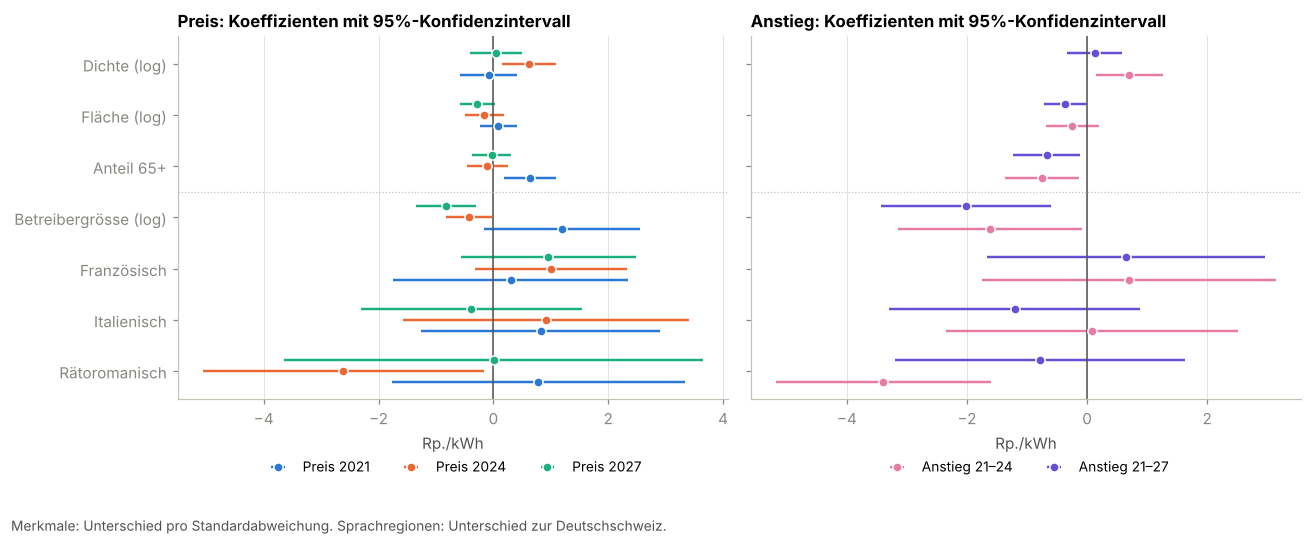

In [8]:
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
zeilen = [NAME[m] for m in MERKMALE] + ["Französisch", "Italienisch", "Rätoromanisch"]
y = np.arange(len(zeilen))[::-1]
for ax, gruppe, titel in [(achsen[0], ["total_2021", "total_2024", "total_2027"], "Preis"),
                          (achsen[1], ["anstieg_21_24", "anstieg_21_27"], "Anstieg")]:
    versatz = np.linspace(-0.22, 0.22, len(gruppe))
    for v, ziel in zip(versatz, gruppe):
        t = modelle_A[ziel]["tabelle"].loc[zeilen]
        ax.errorbar(t["Koeffizient"], y + v, xerr=[t["Koeffizient"] - t["95%-KI unten"],
                    t["95%-KI oben"] - t["Koeffizient"]], fmt="o", ms=6, color=FARBE[ziel],
                    ecolor=FARBE[ziel], elinewidth=1.6, capsize=0, label=ZIELE[ziel],
                    markeredgecolor="white", markeredgewidth=1)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.axhline(3.5, color="#c3c2b7", linewidth=0.8, linestyle=":")
    ax.set_title(f"{titel}: Koeffizienten mit 95%-Konfidenzintervall", loc="left")
    ax.set_xlabel("Rp./kWh")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9)
    ax.grid(axis="y", visible=False)
achsen[0].set_yticks(y, zeilen)
fig.text(0.01, -0.06, "Merkmale: Unterschied pro Standardabweichung. Sprachregionen: Unterschied zur Deutschschweiz.",
         fontsize=9, color="#52514e")
fig.tight_layout()

#### Interpretation der Modellgüte

Das Modell erklärt 22 Prozent der Preisunterschiede 2021, aber nur 7 Prozent 2024 und 2027. Beim Anstieg sind es 21 Prozent (2021 bis 2024) und 29 Prozent (2021 bis 2027). Der RMSE liegt in allen Modellen nur wenig unter der Standardabweichung der Zielgrösse: 2021 zum Beispiel 2.6 gegenüber 3.0 Rp./kWh. Eine typische Vorhersage liegt also immer noch um 2.6 Rappen daneben. Das Modell beschreibt Tendenzen, Preise einzelner Gemeinden kann es nicht bestimmen. Das passt zu Notebook 03: Der Netzbetreiber erklärt 94 bis 97 Prozent der Unterschiede, die Gemeindemerkmale nur einen kleinen Teil davon.

Die Konstante ist der vorhergesagte Preis einer Deutschschweizer Gemeinde mit durchschnittlichen Merkmalen, etwa 20.7 Rp./kWh 2021 und 31.7 Rp./kWh 2024.

#### Interpretation der Koeffizienten

Drei Zusammenhänge haben sich zwischen 2021 und 2024 signifikant verändert. Signifikant heisst hier: Im Modell «Anstieg 21–24» ist der Koeffizient mit p < 0.05 von null verschieden.

1. Anteil 65+. 2021 war eine Gemeinde mit einem um 4.4 Prozentpunkte höheren Anteil älterer Menschen im Mittel 0.64 Rp. teurer (p = 0.005). 2024 besteht kein Zusammenhang mehr (−0.11, p = 0.56). Die Veränderung beträgt −0.75 Rp. (p = 0.018).
2. Dichte. 2021 bestand unter Berücksichtigung der anderen Merkmale kein Zusammenhang (−0.08, p = 0.75). 2024 war eine viermal dichtere Gemeinde im Mittel 0.62 Rp. teurer (p = 0.010). Die Veränderung beträgt +0.70 Rp. (p = 0.014). Der negative Zusammenhang 2021 aus Notebook 03 (Spearman −0.21) verschwindet also, sobald Anteil 65+ und Betreibergrösse berücksichtigt sind.
3. Grösse des Netzbetreibers. Gemeinden grosser Betreiber waren 2021 tendenziell teurer (+1.19, p = 0.085, nicht signifikant), 2024 und 2027 günstiger (−0.43 und −0.82 Rp.). Eine Gemeinde, deren Betreiber achtmal mehr Gemeinden versorgt, hatte von 2021 bis 2027 im Mittel einen um 2.0 Rp. kleineren Anstieg (p = 0.005). Das ist der grösste Koeffizient im Modell.

Die Fläche spielt nur beim Anstieg 2021 bis 2027 eine Rolle (−0.37, p = 0.043). Die Sprachregionen sind nach Berücksichtigung der Merkmale nicht signifikant, mit Ausnahme der rätoromanischen Gemeinden 2024. Diese Ausnahme beruht auf 16 Gemeinden mit wenigen Betreibern und sollte nicht überinterpretiert werden.

Alle Koeffizienten beschreiben Zusammenhänge, keine Ursachen. Die Dichte macht den Strom nicht teurer. Dichte Gemeinden werden von anderen Betreibern versorgt, und diese haben 2022 und 2023 anders eingekauft.

### 3.4 Variante mit Beschäftigten pro Einwohner

Der Anteil Beschäftigte pro Einwohner unterscheidet Arbeitsplatzgemeinden von Wohngemeinden. Er fehlt bei 88 kleinen Gemeinden. Diese Variante prüft, ob er über die anderen Merkmale hinaus etwas erklärt.

In [9]:
mit_b = df.dropna(subset=["beschaeftigte_pro_einw"]).copy()
mit_b["log_beschaeftigte_pro_einw"] = np.log10(mit_b["beschaeftigte_pro_einw"])
NAME["log_beschaeftigte_pro_einw"] = "Beschäftigte pro Einw. (log)"
X_A2 = pd.concat([standardisiert(mit_b, MERKMALE + ["log_beschaeftigte_pro_einw"]),
                  regionen_dummies(mit_b["sprachregion"])], axis=1)
vergleich = {}
for ziel, name in ZIELE.items():
    m = ols_geclustert(mit_b[ziel], X_A2, mit_b["netzbetreiber_id"])
    t = m["tabelle"]
    vergleich[name] = {"R² ohne": modelle_A[ziel]["R2"], "R² mit": m["R2"],
                       "Koef. Beschäftigte": t.loc["Beschäftigte pro Einw. (log)", "Koeffizient"],
                       "p Beschäftigte": t.loc["Beschäftigte pro Einw. (log)", "p"]}
print(f"Variante auf {len(mit_b)} Gemeinden")
pd.DataFrame(vergleich).T.round(3)

Variante auf 1999 Gemeinden

,R² ohne,R² mit,Koef. Beschäftigte,p Beschäftigte
Preis 2021,0.218,0.231,0.269,0.037
Preis 2024,0.068,0.070,-0.237,0.023
Preis 2027,0.069,0.073,-0.161,0.182
Anstieg 21–24,0.214,0.227,-0.506,0.000
Anstieg 21–27,0.290,0.301,-0.430,0.000


#### Interpretation

Die Beschäftigten pro Einwohner erhöhen das R² um höchstens 0.013. Beim Anstieg ist der Koeffizient aber klar signifikant (−0.51 und −0.43 Rp., p < 0.001): Arbeitsplatzgemeinden hatten einen kleineren Anstieg als Wohngemeinden mit denselben übrigen Merkmalen. Weil die Variante 88 kleine Gemeinden verliert und kaum Erklärungskraft dazugewinnt, bleibt Modell A mit allen 2087 Gemeinden das Hauptmodell.

## 4 · Modell B: zusätzlich Kanton

Modell B nimmt für jeden Kanton einen eigenen Achsenabschnitt auf (Kantons-Dummies, Referenz Aargau). Die Sprachregionen fallen weg, weil jeder Kanton fast vollständig in einer Sprachregion liegt.

Zwei Fragen: Wie viel mehr erklärt der Kanton? Und bleiben die Koeffizienten der Gemeindemerkmale bestehen, wenn man nur noch Gemeinden innerhalb desselben Kantons vergleicht?

In [10]:
kanton_dummies = pd.get_dummies(df["kanton"], prefix="KT", drop_first=True).astype(float)
X_B = pd.concat([standardisiert(df, MERKMALE), kanton_dummies], axis=1)
modelle_B = {ziel: ols_geclustert(df[ziel], X_B, df["netzbetreiber_id"]) for ziel in ZIELE}

zeilen_B = []
for ziel, name in ZIELE.items():
    a, b = modelle_A[ziel], modelle_B[ziel]
    eintrag = {"Grösse": name, "R² A": a["R2"], "R² B": b["R2"], "RMSE A": a["RMSE"], "RMSE B": b["RMSE"]}
    for m in MERKMALE:
        eintrag[f"{NAME[m]} B"] = b["tabelle"].loc[NAME[m], "Koeffizient"]
        eintrag[f"p {NAME[m]} B"] = b["tabelle"].loc[NAME[m], "p"]
    zeilen_B.append(eintrag)
pd.DataFrame(zeilen_B).set_index("Grösse").round(3).T

Grösse,Preis 2021,Preis 2024,Preis 2027,Anstieg 21–24,Anstieg 21–27
R² A,0.218,0.068,0.069,0.214,0.290
R² B,0.653,0.267,0.384,0.465,0.569
RMSE A,2.645,3.584,2.941,3.893,3.250
RMSE B,1.761,3.178,2.391,3.211,2.532
Dichte (log) B,0.220,0.482,0.182,0.262,-0.038
p Dichte (log) B,0.034,0.004,0.133,0.074,0.721
Fläche (log) B,0.244,0.197,0.218,-0.047,-0.026
p Fläche (log) B,0.013,0.124,0.011,0.761,0.805
Anteil 65+ B,0.111,0.050,-0.043,-0.061,-0.154
p Anteil 65+ B,0.095,0.716,0.603,0.616,0.047


#### Interpretation

Der Kanton verdreifacht das R² für 2021 von 0.22 auf 0.65 und verdoppelt es für den Anstieg 2021 bis 2027 von 0.29 auf 0.57. Ein grosser Teil dessen, was die Gemeindemerkmale in Modell A erklären, sind also Unterschiede zwischen Kantonen.

Innerhalb desselben Kantons bleiben drei Befunde bestehen:

1. Die Betreibergrösse bleibt in allen fünf Modellen signifikant, mit fast unveränderten Koeffizienten (Anstieg 21–27: −1.55 statt −2.01 Rp., p < 0.001). Sie ist der stabilste Befund.
2. Die Dichte bleibt 2024 signifikant positiv (+0.48 Rp., p = 0.004).
3. Die Fläche wird beim Preisniveau 2021 und 2027 positiv signifikant (+0.24 und +0.22 Rp.): Innerhalb eines Kantons sind grossflächige Gemeinden etwas teurer. Das passt dazu, dass ein grösseres Gebiet mehr Leitungen pro Kunde braucht. In Modell A war dieser Effekt nicht sichtbar. Vermutlich liegen viele grossflächige Gemeinden in Kantonen mit tiefen Preisen, etwa im Wallis und in Graubünden; geprüft ist das nicht.

Der Anteil 65+ verliert dagegen fast seine ganze Wirkung (Anstieg 21–27: −0.15 statt −0.67 Rp., knapp signifikant mit p = 0.047). Der Zusammenhang zwischen Alter und Anstieg in Modell A geht also grösstenteils auf Unterschiede zwischen Kantonen zurück.

## 5 · Modell C: auf Ebene der Netzbetreiber

Auf Gemeindeebene zählt ein grosser Betreiber wie die BKW mit über 300 Gemeinden 300-mal, ein Betreiber mit einer Gemeinde einmal. Modell C zählt jeden Betreiber einmal. Die Merkmale werden dafür pro Betreiber zusammengefasst: Dichte als versorgte Einwohner durch versorgte Fläche, Fläche als Summe, Anteil 65+ als Mittel, Sprachregion als die häufigste. Standardfehler heteroskedastie-robust (HC1), weil es keine Cluster mehr gibt.

In [11]:
def haeufigster(x):
    return x.mode().iloc[0]

betreiber = df.groupby("netzbetreiber_id").agg(
    einwohner=("einwohner", "sum"), flaeche=("flaeche_total", "sum"),
    anteil_65plus=("anteil_65plus", "mean"), groesse=("anz_gemeinden_betreiber", "first"),
    sprachregion=("sprachregion", haeufigster), **{z: (z, "mean") for z in ZIELE})
betreiber["log_dichte"] = np.log10(betreiber["einwohner"] / betreiber["flaeche"])
betreiber["log_flaeche"] = np.log10(betreiber["flaeche"])
betreiber["log_betreibergroesse"] = np.log10(betreiber["groesse"])

X_C = pd.concat([standardisiert(betreiber, MERKMALE), regionen_dummies(betreiber["sprachregion"])], axis=1)
# Jeder Betreiber ist sein eigener Cluster: das ergibt HC1-Standardfehler
modelle_C = {ziel: ols_geclustert(betreiber[ziel], X_C, pd.Series(betreiber.index, index=betreiber.index))
             for ziel in ZIELE}

zeilen_C = []
for ziel, name in ZIELE.items():
    for m in MERKMALE:
        a = modelle_A[ziel]["tabelle"].loc[NAME[m]]
        c = modelle_C[ziel]["tabelle"].loc[NAME[m]]
        zeilen_C.append({"Grösse": name, "Merkmal": NAME[m],
                         "Koef. Gemeinden (A)": a["Koeffizient"], "p (A)": a["p"],
                         "Koef. Betreiber (C)": c["Koeffizient"], "p (C)": c["p"],
                         "robust": (a["p"] < 0.05) and (c["p"] < 0.05)
                                   and np.sign(a["Koeffizient"]) == np.sign(c["Koeffizient"])})
robustheit = pd.DataFrame(zeilen_C)
print("R² auf Betreiberebene:", {ZIELE[z]: round(m["R2"], 3) for z, m in modelle_C.items()})
robustheit.round(3)

R² auf Betreiberebene: {'Preis 2021': np.float64(0.113), 'Preis 2024': np.float64(0.144), 'Preis 2027': np.float64(0.074), 'Anstieg 21–24': np.float64(0.147), 'Anstieg 21–27': np.float64(0.147)}

,Grösse,Merkmal,Koef. Gemeinden (A),p (A),Koef. Betreiber (C),p (C),robust
0,Preis 2021,Dichte (log),-0.081,0.749,0.913,0.000,False
1,Preis 2021,Fläche (log),0.089,0.582,0.580,0.006,False
2,Preis 2021,Anteil 65+,0.641,0.005,0.301,0.043,True
3,Preis 2021,Betreibergrösse (log),1.191,0.085,-0.067,0.717,False
4,Preis 2024,Dichte (log),0.624,0.010,1.549,0.000,True
5,Preis 2024,Fläche (log),-0.160,0.354,-0.627,0.150,False
6,Preis 2024,Anteil 65+,-0.107,0.556,-0.314,0.320,False
7,Preis 2024,Betreibergrösse (log),-0.430,0.036,0.393,0.227,False
8,Preis 2027,Dichte (log),0.044,0.848,0.118,0.730,False
9,Preis 2027,Fläche (log),-0.279,0.070,-0.563,0.080,False


#### Interpretation

Auf Betreiberebene erklären die Merkmale 7 bis 15 Prozent der Unterschiede. Robust auf beiden Ebenen, also signifikant mit gleichem Vorzeichen, sind fünf Befunde:

1. Anteil 65+ und Preis 2021: positiv.
2. Dichte und Preis 2024: positiv.
3. Anteil 65+ und Anstieg 2021 bis 2024: negativ.
4. Anteil 65+ und Anstieg 2021 bis 2027: negativ.
5. Fläche und Anstieg 2021 bis 2027: negativ.

Der wichtigste Befund aus Modell A hält dagegen nicht: Auf Betreiberebene hängt die Betreibergrösse in keinem Modell signifikant mit dem Preis zusammen (p zwischen 0.12 und 0.95). Das ist kein Widerspruch, die beiden Ebenen beantworten verschiedene Fragen. Auf Gemeindeebene zählt ein Betreiber so oft, wie er Gemeinden hat. Die wenigen sehr grossen Betreiber, die zusammen fast die Hälfte der Gemeinden versorgen, hatten einen kleineren Anstieg, und das prägt das Ergebnis. Unter allen 485 Betreibern gilt aber nicht allgemein, dass grössere günstiger sind.

Für die Präsentation heisst das: «Gemeinden, die von einem der grossen Betreiber versorgt werden, hatten einen kleineren Anstieg» ist belegt. «Grosse Betreiber sind günstiger» ist nicht belegt.

Die Dichte beim Anstieg 2021 bis 2027 kehrt sogar das Vorzeichen um (Gemeinden +0.13 und nicht signifikant, Betreiber −0.80 mit p = 0.001). Auch dieser Befund hängt also von der Gewichtung ab.

## 6 · Modellgüte ausserhalb der Stichprobe

R² und RMSE in Abschnitt 3 messen, wie gut das Modell die Daten beschreibt, mit denen es geschätzt wurde. Ob es auf neue Gemeinden übertragbar ist, zeigt erst eine Kreuzvalidierung: Das Modell wird auf vier Fünfteln geschätzt und auf dem fünften Fünftel geprüft, fünfmal reihum.

Entscheidend ist, wie die Fünftel gebildet werden.

- **Zufällig:** Gemeinden desselben Betreibers landen in Training und Test. Das Modell sieht im Training schon Gemeinden mit genau dem Preis, den es im Test vorhersagen soll.
- **Nach Netzbetreiber gruppiert:** Alle Gemeinden eines Betreibers liegen im selben Fünftel. Das Modell muss Gemeinden von Betreibern vorhersagen, die es nie gesehen hat. Das ist die ehrliche Prüfung.

Vergleichsmassstab ist eine Vorhersage ohne Merkmale: der Mittelwert der Trainingsdaten. Das R² ausserhalb der Stichprobe misst, um wie viel das Modell besser ist als dieser Mittelwert. Ein negativer Wert heisst, dass es schlechter ist.

In [12]:
def kreuzvalidierung(y: pd.Series, X: pd.DataFrame, verfahren, gruppen=None) -> dict:
    yv = y.to_numpy(float)
    vorhersage, basis = np.zeros(len(yv)), np.zeros(len(yv))
    for train, test in verfahren.split(X, groups=gruppen):
        vorhersage[test] = LinearRegression().fit(X.iloc[train], yv[train]).predict(X.iloc[test])
        basis[test] = yv[train].mean()
    rmse = np.sqrt(np.mean((yv - vorhersage) ** 2))
    rmse_basis = np.sqrt(np.mean((yv - basis) ** 2))
    return {"RMSE": rmse, "RMSE Mittelwert": rmse_basis, "R² ausserhalb": 1 - rmse ** 2 / rmse_basis ** 2}

cv = []
for ziel, name in ZIELE.items():
    zufall = kreuzvalidierung(df[ziel], X_A, KFold(5, shuffle=True, random_state=42))
    gruppiert = kreuzvalidierung(df[ziel], X_A, GroupKFold(5), df["netzbetreiber_id"])
    cv.append({"Grösse": name, "R² in der Stichprobe": modelle_A[ziel]["R2"],
               "R² zufällige Folds": zufall["R² ausserhalb"], "R² gruppierte Folds": gruppiert["R² ausserhalb"],
               "RMSE gruppiert": gruppiert["RMSE"], "RMSE Mittelwert": gruppiert["RMSE Mittelwert"]})
cv = pd.DataFrame(cv).set_index("Grösse")
cv.round(3)

,R² in der Stichprobe,R² zufällige Folds,R² gruppierte Folds,RMSE gruppiert,RMSE Mittelwert
Grösse,,,,,
Preis 2021,0.218,0.213,-0.104,3.406,3.242
Preis 2024,0.068,0.060,-0.007,3.769,3.756
Preis 2027,0.069,0.063,-0.025,3.117,3.078
Anstieg 21–24,0.214,0.210,-0.058,4.779,4.646
Anstieg 21–27,0.290,0.286,-0.050,4.255,4.153


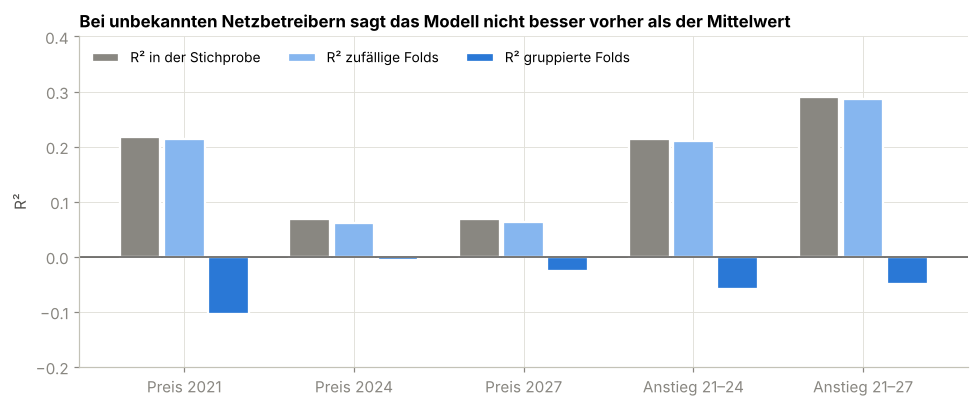

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
spalten = ["R² in der Stichprobe", "R² zufällige Folds", "R² gruppierte Folds"]
farben = ["#898781", "#86b6ef", "#2a78d6"]
x = np.arange(len(cv))
for i, (sp, fa) in enumerate(zip(spalten, farben)):
    ax.bar(x + (i - 1) * 0.26, cv[sp], width=0.24, color=fa, label=sp, edgecolor="white", linewidth=1.5)
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_xticks(x, cv.index)
ax.set_ylabel("R²")
ax.set_title("Bei unbekannten Netzbetreibern sagt das Modell nicht besser vorher als der Mittelwert", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper left", fontsize=9)
ax.set_ylim(-0.2, 0.4)
fig.tight_layout()

#### Interpretation

Mit zufälligen Folds liegt das R² fast gleich hoch wie in der Stichprobe (zum Beispiel 0.286 gegenüber 0.290 beim Anstieg 2021 bis 2027). Überangepasst ist das Modell also nicht.

Mit nach Netzbetreiber gruppierten Folds ist das R² in allen fünf Modellen negativ, zwischen −0.10 und −0.01. Für Gemeinden eines Betreibers, den das Modell nicht kennt, ist die Vorhersage aus den Gemeindemerkmalen schlechter als einfach der Mittelwert. Beim Preis 2021 liegt der RMSE bei 3.41 Rp. gegenüber 3.24 Rp. für den Mittelwert.

Der Unterschied zwischen den beiden Verfahren zeigt, woher die Erklärungskraft stammt: Bei zufälligen Folds kennt das Modell den Preis eines Betreibers schon aus dessen anderen Gemeinden. Das R² in der Stichprobe misst also vor allem, wie gut sich die Betreiber in den Daten auseinanderhalten lassen, nicht, wie gut Gemeindemerkmale einen Strompreis bestimmen.

Daraus folgt für die Forschungsfrage: Die Merkmale eignen sich, um Zusammenhänge zu beschreiben und ihre Veränderung über die Zeit zu vergleichen. Für die Vorhersage des Strompreises einer Gemeinde taugen sie nicht. Dazu müsste man den Netzbetreiber und seine Beschaffung kennen, und diese Information enthalten die Daten nicht.

## 7 · Residuen

Geprüft am Modell für den Anstieg 2021 bis 2027, dem Modell mit dem höchsten R².

Schiefe 0.15, Kurtosis 0.53
Anteil der Residuenstreuung zwischen Netzbetreibern: 90.4%

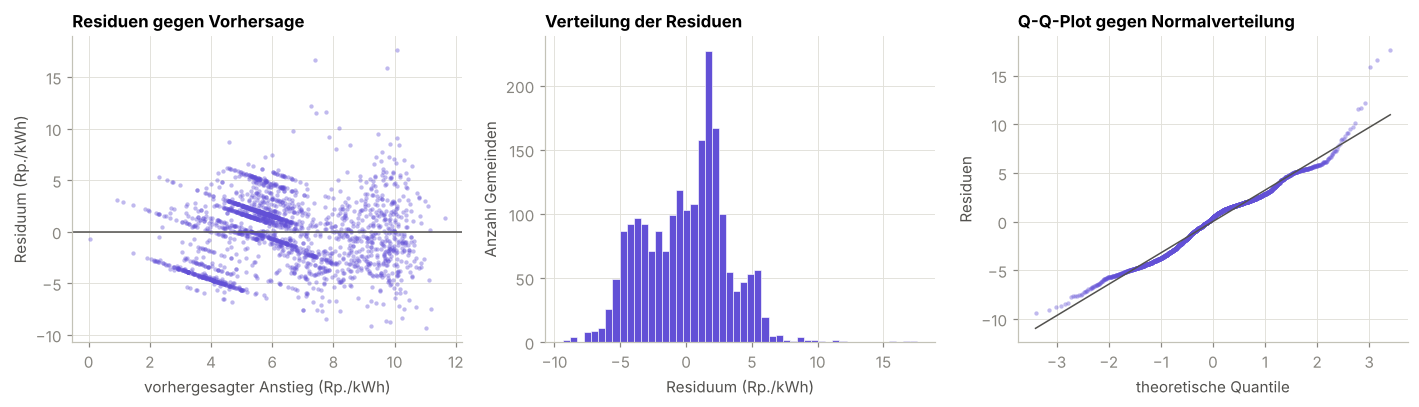

In [14]:
m = modelle_A["anstieg_21_27"]
fig, achsen = plt.subplots(1, 3, figsize=(13, 3.8))
achsen[0].scatter(m["vorhersage"], m["resid"], s=8, alpha=0.4, color="#6250d6", linewidths=0)
achsen[0].axhline(0, color="#52514e", linewidth=1)
achsen[0].set_xlabel("vorhergesagter Anstieg (Rp./kWh)"); achsen[0].set_ylabel("Residuum (Rp./kWh)")
achsen[0].set_title("Residuen gegen Vorhersage", loc="left")

achsen[1].hist(m["resid"], bins=50, color="#6250d6", edgecolor="white", linewidth=0.4)
achsen[1].set_xlabel("Residuum (Rp./kWh)"); achsen[1].set_ylabel("Anzahl Gemeinden")
achsen[1].set_title("Verteilung der Residuen", loc="left")

(osm, osr), (steigung, achse, _) = stats.probplot(m["resid"], dist="norm")
achsen[2].scatter(osm, osr, s=8, alpha=0.4, color="#6250d6", linewidths=0)
achsen[2].plot(osm, steigung * osm + achse, color="#52514e", linewidth=1)
achsen[2].set_xlabel("theoretische Quantile"); achsen[2].set_ylabel("Residuen")
achsen[2].set_title("Q-Q-Plot gegen Normalverteilung", loc="left")
fig.tight_layout()

resid = pd.Series(m["resid"])
print(f"Schiefe {resid.skew():.2f}, Kurtosis {resid.kurt():.2f}")
print(f"Anteil der Residuenstreuung zwischen Netzbetreibern: "
      f"{resid.groupby(df['netzbetreiber_id'].to_numpy()).transform('mean').var() / resid.var():.1%}")

#### Interpretation

Die Residuen sind annähernd symmetrisch (Schiefe 0.15) und nur leicht breiter als eine Normalverteilung (Kurtosis 0.53). Im Q-Q-Plot weichen nur die grössten positiven Residuen ab: einige Gemeinden mit einem viel stärkeren Anstieg als vorhergesagt. Ein Trichtermuster im linken Diagramm, also eine mit der Vorhersage wachsende Streuung, ist nicht zu sehen.

Auffällig sind die schrägen Linien im linken Diagramm. Jede Linie ist ein Netzbetreiber: Seine Gemeinden haben alle denselben Anstieg, aber unterschiedliche Merkmale und damit unterschiedliche Vorhersagen. Daher die Steigung von −1. Die mehrgipfelige Verteilung der Residuen kommt ebenfalls von den grossen Betreibern.

90 Prozent der Residuenstreuung liegt zwischen den Netzbetreibern. Die Residuen sind also stark abhängig, was die nach Betreiber geclusterten Standardfehler nötig macht. Gewöhnliche Standardfehler hätten die Unsicherheit deutlich unterschätzt.

## 8 · k-means: Gemeindetypen

Die Regression fragt, wie einzelne Merkmale mit dem Preis zusammenhängen. k-means fragt anders: Gibt es Gruppen von Gemeinden, die sich in ihren Merkmalen ähnlich sind, und waren diese Gruppen unterschiedlich stark vom Anstieg betroffen?

Geclustert wird nur auf den Gemeindemerkmalen, nicht auf den Preisen. Sonst wäre der Vergleich der Preise zwischen den Clustern zirkulär.

### 8.1 Merkmale und Skalierung
Verwendet werden Dichte (log), Fläche (log) und Anteil 65+, also die Eigenschaften der Gemeinde selbst. Die Betreibergrösse bleibt draussen, weil sie keine Eigenschaft der Gemeinde ist. k-means misst Abstände, deshalb werden alle drei Merkmale standardisiert, sonst würde das Merkmal mit der grössten Spannweite die Cluster bestimmen.

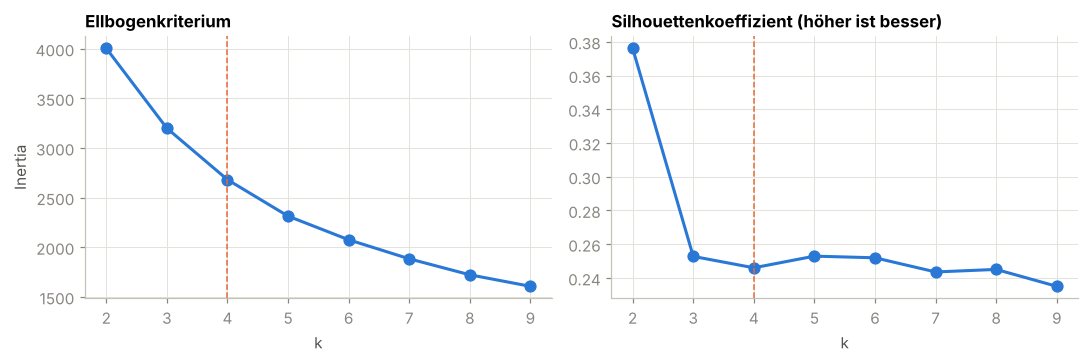

,Inertia,Silhouette
k,,
2,4004.379,0.376
3,3199.220,0.253
4,2681.056,0.246
5,2313.754,0.253
6,2075.539,0.252
7,1883.708,0.244
8,1722.582,0.245
9,1606.464,0.235


In [15]:
CLUSTER_MERKMALE = ["log_dichte", "log_flaeche", "anteil_65plus"]
Z = StandardScaler().fit_transform(df[CLUSTER_MERKMALE])

auswahl = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z)
    auswahl.append({"k": k, "Inertia": km.inertia_, "Silhouette": silhouette_score(Z, km.labels_)})
auswahl = pd.DataFrame(auswahl).set_index("k")

fig, achsen = plt.subplots(1, 2, figsize=(10, 3.4))
achsen[0].plot(auswahl.index, auswahl["Inertia"], marker="o", color="#2a78d6", linewidth=2, ms=7)
achsen[0].set_title("Ellbogenkriterium", loc="left"); achsen[0].set_xlabel("k"); achsen[0].set_ylabel("Inertia")
achsen[1].plot(auswahl.index, auswahl["Silhouette"], marker="o", color="#2a78d6", linewidth=2, ms=7)
achsen[1].set_title("Silhouettenkoeffizient (höher ist besser)", loc="left"); achsen[1].set_xlabel("k")
for ax in achsen:
    ax.axvline(4, color="#eb6834", linewidth=1, linestyle="--")
fig.tight_layout()
auswahl.round(3)

### 8.2 Wahl von k

Das Ellbogenkriterium zeigt keinen klaren Knick. Der Silhouettenkoeffizient ist bei k = 2 am höchsten, zwei Cluster trennen aber nur grob Stadt und Land. Von k = 3 bis k = 6 liegt die Silhouette fast gleich (Unterschiede unter 0.01). Die Daten erzwingen also keine bestimmte Zahl, die Wahl ist eine inhaltliche.

Gewählt wird **k = 4**, weil die vier Cluster klar unterscheidbare und benennbare Gemeindetypen ergeben (Abschnitt 8.3) und alle Cluster gross genug sind (über 200 Gemeinden). Ein Silhouettenwert um 0.25 bedeutet, dass die Cluster eine erkennbare, aber keine scharfe Struktur haben: Die Gemeindetypen gehen fliessend ineinander über.

In [16]:
km = KMeans(n_clusters=4, n_init=20, random_state=42).fit(Z)
df["cluster_roh"] = km.labels_

profil = df.groupby("cluster_roh").agg(
    Gemeinden=("gemeinde_nr", "size"), Dichte_Median=("dichte", "median"),
    Flaeche_Median=("flaeche_total", "median"), Anteil_65plus=("anteil_65plus", "mean"),
    Einwohner_Median=("einwohner", "median"))

# Benennung nach Profil (unabhängig von der zufälligen Nummerierung durch k-means)
namen = {}
namen[profil["Dichte_Median"].idxmax()] = "Städtisch, dicht"
namen[profil["Flaeche_Median"].idxmax()] = "Ländlich-alpin, gross und älter"
rest = [c for c in profil.index if c not in namen]
namen[min(rest, key=lambda c: profil.loc[c, "Anteil_65plus"])] = "Agglomeration, jung"
namen[[c for c in rest if c not in namen][0]] = "Ländlich, mittel"
assert len(set(namen.values())) == 4
REIHENFOLGE = ["Städtisch, dicht", "Agglomeration, jung", "Ländlich, mittel", "Ländlich-alpin, gross und älter"]
df["gemeindetyp_km"] = pd.Categorical(df["cluster_roh"].map(namen), REIHENFOLGE, ordered=True)
TYP_FARBE = dict(zip(REIHENFOLGE, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

profil.index = profil.index.map(namen)
profil.reindex(REIHENFOLGE).round(1)

,Gemeinden,Dichte_Median,Flaeche_Median,Anteil_65plus,Einwohner_Median
cluster_roh,,,,,
"Städtisch, dicht",563,626.2,4.7,21.5,2914.0
"Agglomeration, jung",627,254.5,5.4,15.3,1298.0
"Ländlich, mittel",666,109.8,16.2,19.1,1756.5
"Ländlich-alpin, gross und älter",231,19.2,53.5,26.0,838.0


### 8.3 Profil der Cluster

Die Benennung folgt dem Profil: dichte, kleinflächige Zentren; junge Agglomerationsgemeinden mittlerer Dichte; ländliche Gemeinden mittlerer Grösse; dünn besiedelte, grossflächige Gemeinden mit dem höchsten Anteil älterer Menschen.

Zur Kontrolle der Vergleich mit der offiziellen Gemeindetypologie des BFS (2012, 9 Typen), die k-means nicht kannte. Die Codes: 11 bis 13 städtisch, 21 bis 23 periurban, 31 bis 33 ländlich.

In [17]:
pd.crosstab(df["gemeindetyp_km"], df["gemeindetyp_9"].astype("Int64"), margins=True, margins_name="Total")

gemeindetyp_9,11,12,13,21,22,23,31,32,33,Total
gemeindetyp_km,,,,,,,,,,
"Städtisch, dicht",99,126,49,48,93,70,10,63,5,563
"Agglomeration, jung",52,29,25,33,158,187,9,126,7,626
"Ländlich, mittel",9,33,43,23,100,158,41,177,82,666
"Ländlich-alpin, gross und älter",0,0,3,0,9,34,23,8,154,231
Total,160,188,120,104,360,449,83,374,248,2086


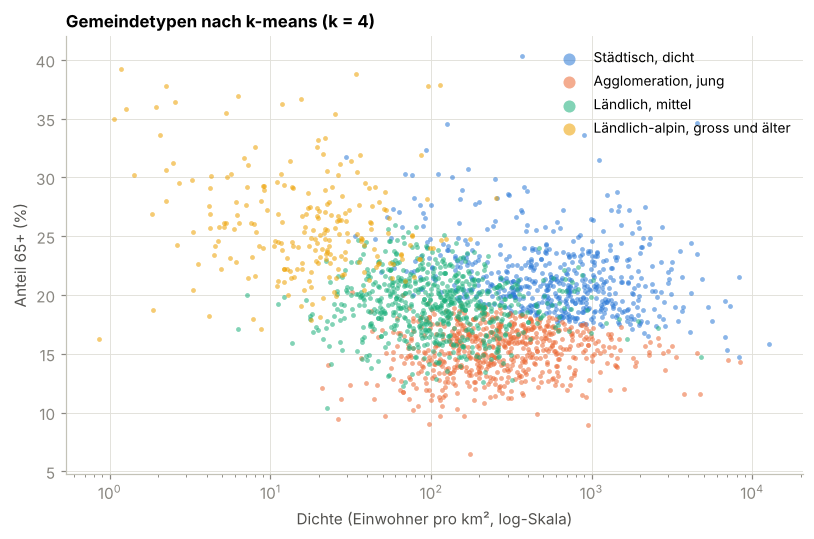

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for typ in REIHENFOLGE:
    t = df[df["gemeindetyp_km"] == typ]
    ax.scatter(t["dichte"], t["anteil_65plus"], s=10, alpha=0.55, color=TYP_FARBE[typ], label=typ, linewidths=0)
ax.set_xscale("log")
ax.set_xlabel("Dichte (Einwohner pro km², log-Skala)")
ax.set_ylabel("Anteil 65+ (%)")
ax.set_title("Gemeindetypen nach k-means (k = 4)", loc="left")
ax.legend(frameon=False, markerscale=2.5, fontsize=9, loc="upper right")
fig.tight_layout()

### 8.4 Waren die Gemeindetypen unterschiedlich betroffen?

ANOVA über die vier Cluster pro Zielgrösse. Wie in Notebook 03 ist die ANOVA auf Gemeindeebene zu optimistisch, weil die Gemeinden eines Betreibers nicht unabhängig sind. Deshalb zusätzlich ein cluster-robuster Wald-Test: eine Regression der Zielgrösse auf die Cluster-Dummies mit nach Netzbetreiber geclusterten Standardfehlern, getestet wird, ob alle Unterschiede zwischen den Clustern gleich null sind.

In [19]:
mittel_typ = df.groupby("gemeindetyp_km", observed=True)[list(ZIELE)].mean().rename(columns=ZIELE)
typ_dummies = pd.get_dummies(df["gemeindetyp_km"], drop_first=True).astype(float)

tests = []
for ziel, name in ZIELE.items():
    gruppen = [g[ziel].to_numpy() for _, g in df.groupby("gemeindetyp_km", observed=True)]
    f = stats.f_oneway(*gruppen)
    gesamt = ((df[ziel] - df[ziel].mean()) ** 2).sum()
    zwischen = sum(len(g) * (g.mean() - df[ziel].mean()) ** 2 for g in gruppen)
    modell = ols_geclustert(df[ziel], typ_dummies, df["netzbetreiber_id"])
    F_w, p_w = wald_test(modell, [1, 2, 3])
    tests.append({"Grösse": name, "F (ANOVA)": f.statistic, "p (ANOVA)": f.pvalue,
                  "eta²": zwischen / gesamt, "F (Wald, geclustert)": F_w, "p (Wald, geclustert)": p_w})
print(mittel_typ.round(2), "\n")
pd.DataFrame(tests).set_index("Grösse").round(4)

                                 Preis 2021  Preis 2024  Preis 2027  Anstieg 21–24  Anstieg 21–27
gemeindetyp_km                                                                                   
Städtisch, dicht                      21.01       32.33       27.29          11.33           6.29
Agglomeration, jung                   20.12       32.44       27.27          12.32           7.15
Ländlich, mittel                      21.26       31.88       27.48          10.62           6.23
Ländlich-alpin, gross und älter       21.38       30.22       26.42           8.84           5.04 

,F (ANOVA),p (ANOVA),eta²,"F (Wald, geclustert)","p (Wald, geclustert)"
Grösse,,,,,
Preis 2021,19.8842,0.0000,0.0278,1.6805,0.1703
Preis 2024,23.0837,0.0000,0.0322,3.3780,0.0182
Preis 2027,7.1498,0.0001,0.0102,1.4909,0.2162
Anstieg 21–24,41.9425,0.0000,0.0570,7.6143,0.0001
Anstieg 21–27,18.5868,0.0000,0.0261,4.9679,0.0021


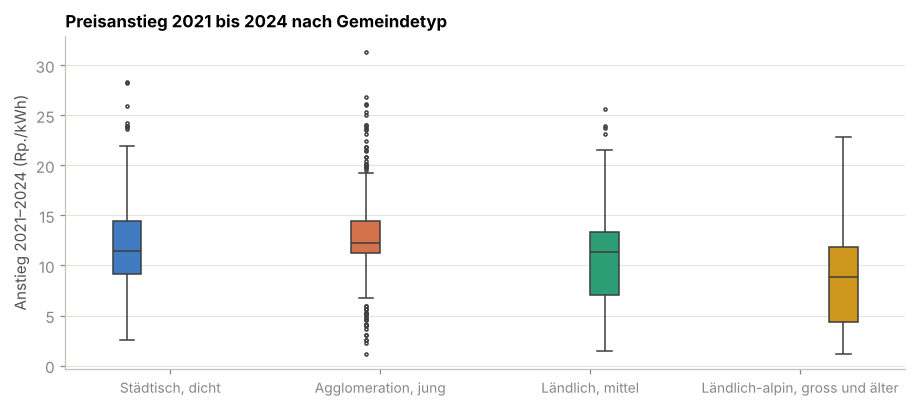

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sns.boxplot(data=df, x="gemeindetyp_km", y="anstieg_21_24", hue="gemeindetyp_km", palette=TYP_FARBE,
            legend=False, width=0.55, fliersize=2, linewidth=1, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Anstieg 2021–2024 (Rp./kWh)")
ax.set_title("Preisanstieg 2021 bis 2024 nach Gemeindetyp", loc="left")
ax.tick_params(axis="x", labelsize=9)
fig.tight_layout()

#### Interpretation

Die vier Cluster decken sich gut mit der offiziellen BFS-Typologie, obwohl k-means sie nicht kannte. Von den 231 Gemeinden im Cluster «Ländlich-alpin» gehören 154 zum BFS-Typ 33 (ländliche periphere Gemeinde). Im Cluster «Städtisch, dicht» liegen 274 der 563 Gemeinden in den städtischen Typen 11 bis 13. Die Agglomerationsgemeinden verteilen sich vor allem auf die periurbanen Typen 22 und 23 sowie auf den ländlich zentralen Typ 32.

Im Preisanstieg unterscheiden sich die Typen deutlich. Von 2021 bis 2024 stieg der Preis in den ländlich-alpinen Gemeinden im Mittel um 8.8 Rp., in den jungen Agglomerationsgemeinden um 12.3 Rp. Auch 2027 sind die ländlich-alpinen Gemeinden mit 26.4 Rp. am günstigsten, die übrigen liegen zwischen 27.3 und 27.5 Rp.

Die gewöhnliche ANOVA ist für alle fünf Grössen hochsignifikant, erklärt aber nur 1 bis 6 Prozent der Streuung. Der cluster-robuste Wald-Test trennt schärfer: Signifikant sind die Unterschiede beim Anstieg 2021 bis 2024 (p = 0.0001), beim Anstieg 2021 bis 2027 (p = 0.002) und beim Preis 2024 (p = 0.018). Beim Preis 2021 (p = 0.17) und 2027 (p = 0.22) sind sie es nicht.

Die Gemeindetypen unterscheiden sich also nicht im Preisniveau vor oder nach der Krise, sondern darin, wie stark die Krise sie getroffen hat. Das bestätigt mit einer zweiten Methode, was Modell A zeigt: Die Zusammenhänge zwischen Gemeindemerkmalen und Preis gelten nicht in allen drei Jahren gleich.

## 9 · Fazit

### Antwort auf die Forschungsfrage

Welche Merkmale erklären die Höhe des Strompreises? Gemeindemerkmale erklären wenig: 7 bis 29 Prozent der Unterschiede auf Gemeindeebene, und bei Gemeinden unbekannter Netzbetreiber nichts. Der Strompreis einer Gemeinde hängt vor allem davon ab, wer sie versorgt. Am stabilsten ist der Zusammenhang mit der Grösse des Netzbetreibers: Gemeinden der grossen Betreiber hatten einen kleineren Anstieg. Dieser Befund beruht aber auf wenigen sehr grossen Betreibern und gilt nicht für Betreiber allgemein.

Haben sich die Zusammenhänge verändert? Ja. Vor der Krise waren Gemeinden mit vielen älteren Menschen teurer, die Dichte spielte keine Rolle. Auf dem Höhepunkt 2024 waren dichte Gemeinden teurer, das Alter spielte keine Rolle mehr. Beide Veränderungen sind auf Gemeindeebene signifikant. Auf Betreiberebene hält die beim Alter, die bei der Dichte verfehlt die Signifikanz knapp (p = 0.059). Die ländlich-alpinen Gemeinden traf der Anstieg am wenigsten. 2027 erklären die Merkmale kaum noch etwas.

### Abdeckung der Anforderungen

| Anforderung | Wo |
|---|---|
| Pflicht 5: Regression mit Vergleich über Zeiträume | Abschnitt 3, formaler Test der Veränderung über die Anstiegsmodelle |
| Pflicht 6: Gütemasse | R², R² adj. und RMSE in Abschnitt 3, Kreuzvalidierung in Abschnitt 6 |
| Pflicht 7: Interpretation | Interpretationen in den Abschnitten 3 bis 8 |
| Bonus 4: Test mit p-Wert | ANOVA in Abschnitt 8.4, zusätzlich zu Notebook 03 |
| Bonus 5: k-means zusätzlich zum Modell | Abschnitt 8 |

### Einschränkungen

- Die Gemeindemerkmale stammen aus 2016 bis 2019, die Preise aus 2021 bis 2027.
- Die Netzbetreiber-Zuordnung beruht auf dem Tarifjahr 2027. Fusionen von Betreibern zwischen 2021 und 2027 sind nicht berücksichtigt.
- Wie die Betreiber ihren Strom beschaffen (eigene Produktion, langfristige Verträge, Kauf am Markt), steht nicht in den Daten. Genau das dürfte die Unterschiede von 2024 am stärksten erklären.
- Alle Ergebnisse sind Zusammenhänge, keine Ursachen.